In [1]:
from MultiAgent_DQ import *
import numpy as np
import pandas as pd  
import itertools
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import pandas as pd
import sys
sys.path.append('../')
import tqdm
from utils import *

## Proposition17


In [2]:
from basin import (
    calculate_B_hat,
    calculate_C_hat,
    calculate_D_hat,
    get_aggregate_bounds_prop17,
    theoretical_P_AD_from_ADGT,
    plot_adgt_boa_validation,
    plot_acgt_boundary_validation,
    plot_acad_entry_validation,
    sample_acad_entry_points,
    verify_trajectory_in_basin,
)
from MultiAgent_DQ import Algorithm
from utils import convert_dict_to_mean_df


def theoretical_P_GT_from_ADGT(t, r, p, s, epsilon=None, delta=None, state_idx=0, e=None):
  """B_hat = BoA(pi^GT | (AD,GT))."""
  if epsilon is None:
    epsilon = e
  return calculate_B_hat(t=t, r=r, p=p, s=s, epsilon=epsilon, d=delta, state_idx=state_idx)


def theoretical_C_hat_from_ACGT(t, r, p, s, epsilon=None, delta=None, e=None):
  if epsilon is None:
    epsilon = e
  return calculate_C_hat(t=t, r=r, p=p, s=s, epsilon=epsilon, d=delta)


def theoretical_D_hat_from_ACAD(t, r, p, s, epsilon=None, delta=None, e=None):
  if epsilon is None:
    epsilon = e
  return calculate_D_hat(t=t, r=r, p=p, s=s, epsilon=epsilon, d=delta)



## reading results from simulations


In [3]:
df = pd.read_csv("../results/results_from_vectorized_script_raw.csv")
df_08_05 = pd.read_csv('../results/results_vect_ADGT_0.8_0.5_more_e.csv')
df_07_02 = pd.read_csv('../results/results_vect_ADGT_0.7_0.2_more_e.csv')
df_08_05_uniform = pd.read_csv('../results/results_vect_uniform_0.8_0.5_more_e.csv')
df_07_02_uniform = pd.read_csv('../results/results_vect_uniform_0.7_0.2_more_e.csv')



In [4]:
df_2000_0702 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/2000_0702.csv')
df_2000_0805 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/2000_0805.csv')


In [5]:
df_ACGT0805 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ACGT.csv')
df_ACGT0702 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ACGT0702.csv')
df_ADGT0805 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ADGT.csv')[:225]
df_ADGT0702 = pd.read_csv('/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ADGT.csv')[225:]

import os
_acad_candidates = [
    '/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ACAD0702.csv',
    '/Users/giuseppe.martucci/Desktop/DecPartialBatch_Q/results/results_vect_paramsfixed_time2000_ACAD.csv',
]
df_ACAD0702 = pd.read_csv(_acad_candidates[0]) if os.path.exists(_acad_candidates[0]) else None
df_ACAD0805 = pd.read_csv(_acad_candidates[1]) if os.path.exists(_acad_candidates[1]) else None


In [6]:
def round_columns(df, columns, decimals):
    for column in columns:
        df[column] = df[column].round(decimals)
    return df

def round_to_quarters(df, columns, decimals):
    for column in columns:
        df[column] = (df[column]/ 0.25).round(decimals)* 0.25
    return df




In [7]:
#columns = ['delta', 'e', 'lambda', 'alpha']

# Generate all pairwise combinations of the columns
#pair_combinations = list(itertools.combinations(columns, 2))


In [8]:
#heatmap_3d_voxels(df_08_05, 'delta', 'lambda', 'alpha', value='P_AD')
#heatmap_3d_voxels(df_07_02, 'delta', 'lambda', 'alpha', value='P_AD')


In [9]:
#interactive_3d_voxel(df, 'delta', 'lambda', 'alpha', value='P_AD', html= False)


In [10]:
#heatmap_mean(df, 'delta', 'e', 'P_AD')


In [11]:
def filter_for_plot(df, na = 5, nl = 8):
    alphas = np.sort(df['alpha'].unique())
    selected = alphas[np.linspace(0, len(alphas) - 1, na).astype(int)]
    lambdas = np.sort(df['lambda'].unique())
    selected_l = lambdas[np.linspace(0, len(lambdas) - 1, nl).astype(int)]
    stric_s = selected_l[:-3]
    df_filtered = df[df['alpha'].isin(selected)]
    df_filtered = df_filtered[df_filtered['lambda'].isin(stric_s)]
    return df_filtered


In [12]:
df_filtered = filter_for_plot(df_07_02, na = 5, nl = 8)
print('alpha values:',df_filtered['alpha'].unique())
print('lambda values:', df_filtered['lambda'].unique())


alpha values: [0.01  0.258 0.505 0.753 1.   ]
lambda values: [0.01  0.092 0.216 0.34  0.422]


In [13]:
df_filtered.M.value_counts()


M
20     375
100    375
500    300
Name: count, dtype: int64

## Uniform Initialization


In [14]:
from basin import *


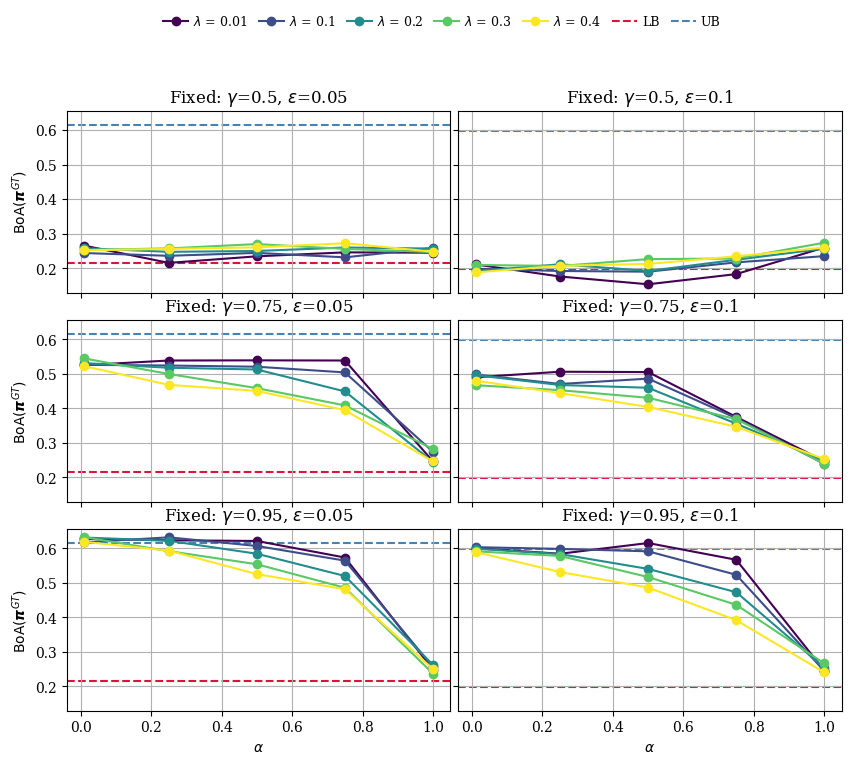

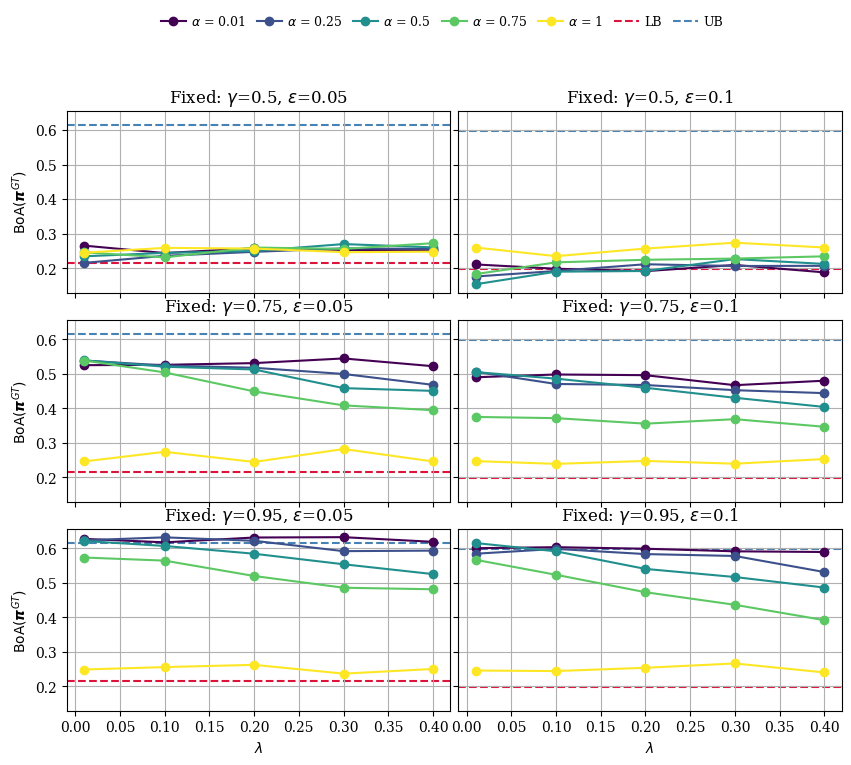

In [15]:
#df_07_02_uniform_filtered = filter_for_plot(df_07_02_uniform, na = 5, nl = 8)
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

y = 'P_GT'

t, r, p, s = 1, 0.7, 0.2, 0
theoretical_bounds = [get_aggregate_bounds_prop17(t=t, r=r, p=p, s=s, epsilon=ps['e'], delta=ps['delta']) for ps in param_sets]


plot_multiple_panels(df_2000_0702, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=2000, use_same_scale=True, cmap = 'viridis', theoretical_bounds=theoretical_bounds, theoretical_bounds_labels=("LB", "UB"), y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$")
plot_multiple_panels(df_2000_0702, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=2000, use_same_scale=True, cmap = 'viridis', theoretical_bounds=theoretical_bounds, theoretical_bounds_labels=("LB", "UB"), y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$")


In [16]:
e, delta = 0.05, 0.95
t, r, p, s = 1, 0.8, 0.5, 0
get_aggregate_bounds(t=t, r=r, p=p, s=s, epsilon=e, d=delta, P_AD = True)


(0.35697499999999993, 0.763821590909091)

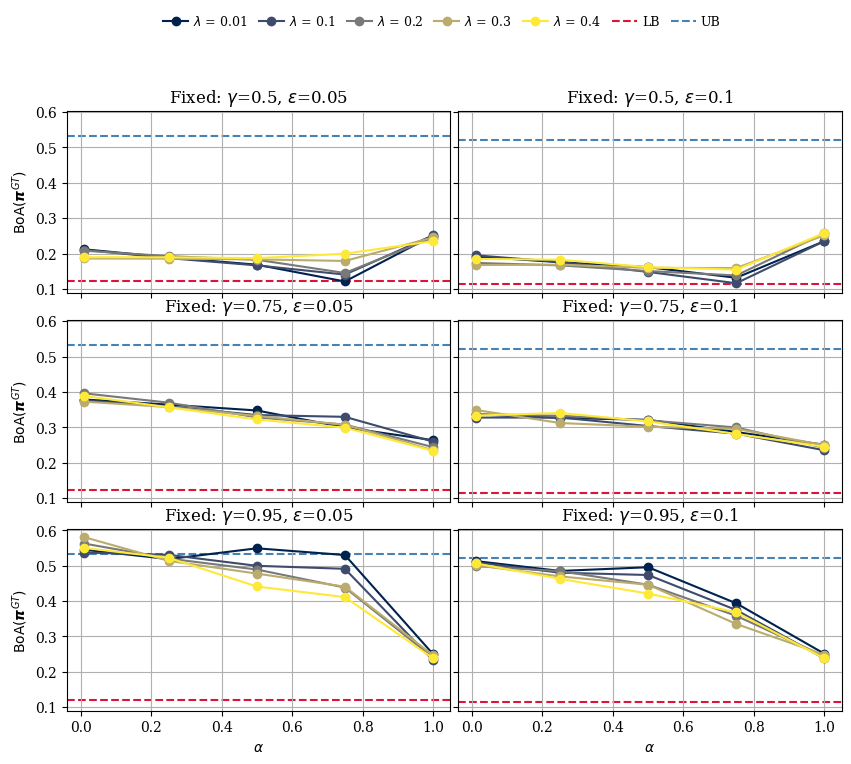

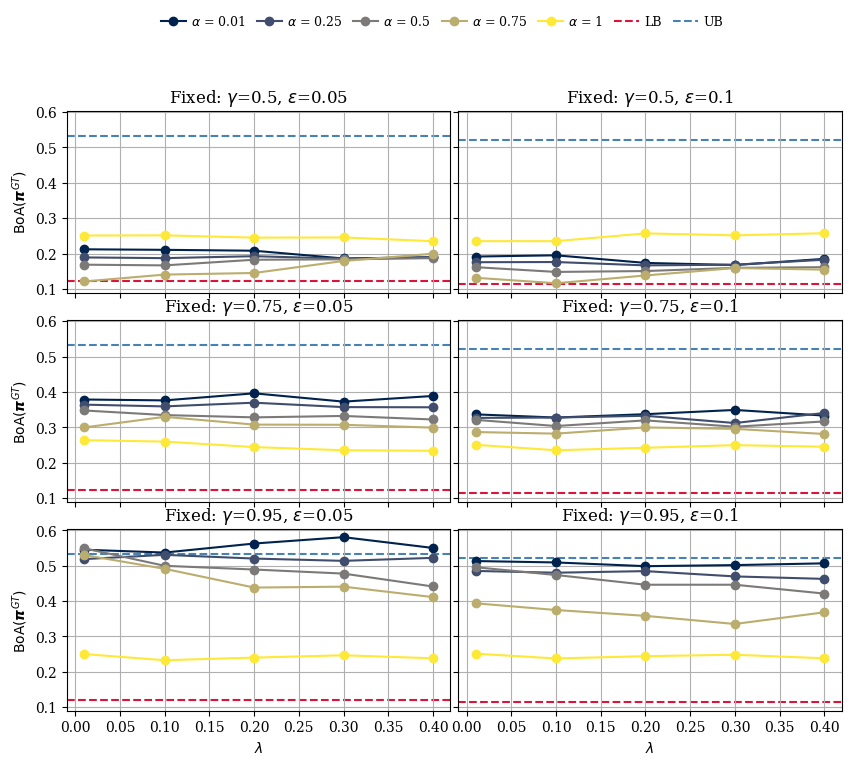

In [17]:
#df_08_05_uniform_filtered = filter_for_plot(df_08_05_uniform, na = 5, nl = 8)
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]


y = 'P_GT'

t, r, p, s = 1, 0.8, 0.5, 0
theoretical_bounds = [get_aggregate_bounds_prop17(t=t, r=r, p=p, s=s, epsilon=ps['e'], delta=ps['delta']) for ps in param_sets]


plot_multiple_panels(df_2000_0805, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_bounds=theoretical_bounds, theoretical_bounds_labels=("LB", "UB"), y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$")
plot_multiple_panels(df_2000_0805, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_bounds=theoretical_bounds, theoretical_bounds_labels=("LB", "UB"), y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$")


## ADGT plots


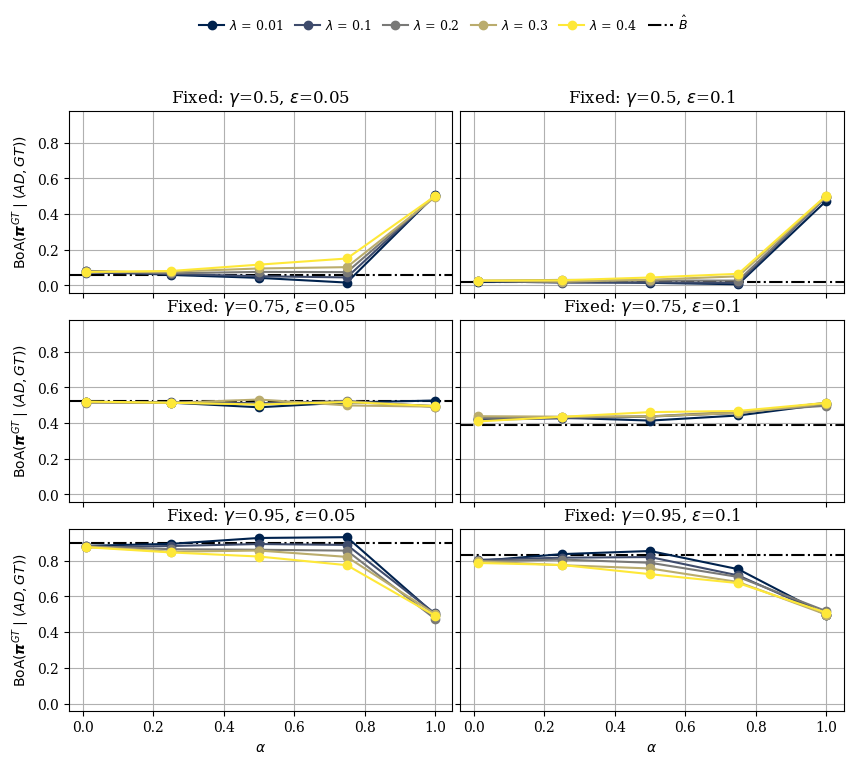

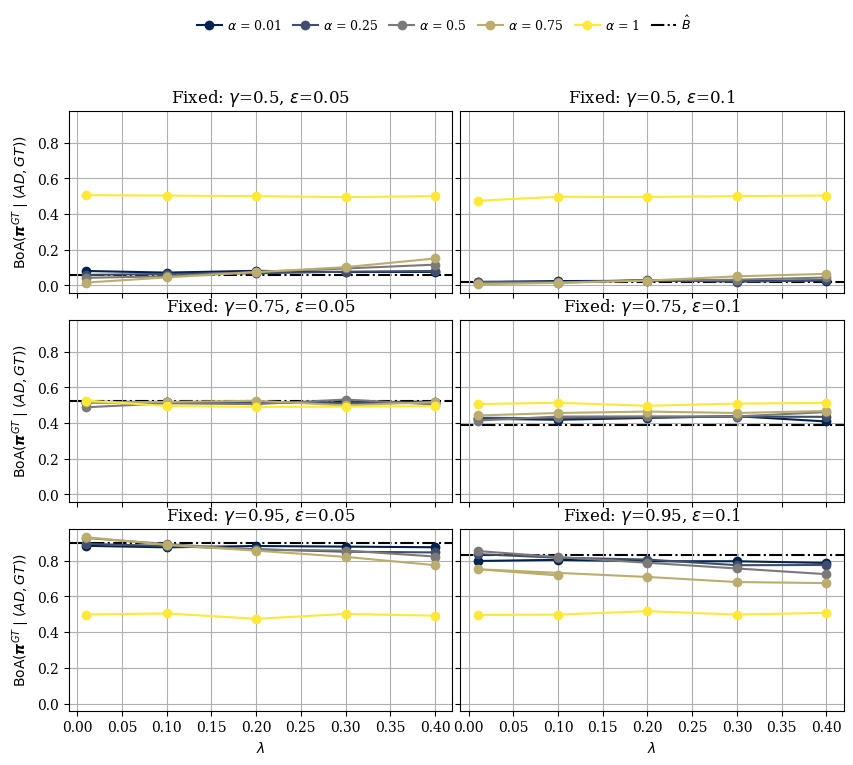

In [18]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]


y = 'P_GT'

t, r, p, s = 1, 0.8, 0.5, 0
from MultiAgent.basin import theoretical_P_AD_from_ADGT

theoretical_per_panel = [theoretical_P_GT_from_ADGT(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']) for ps in param_sets]
theoretical_per_panel_c_s = [theoretical_P_GT_from_ADGT(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']) for ps in param_sets]

plot_multiple_panels(df_ADGT0805, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_basin_AD=theoretical_per_panel_c_s, y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AD,GT))$", theoretical_line_label=r"$\hat{B}$")
plot_multiple_panels(df_ADGT0805, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=2000, use_same_scale=True, cmap = 'cividis', theoretical_basin_AD=theoretical_per_panel_c_s, y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AD,GT))$", theoretical_line_label=r"$\hat{B}$")


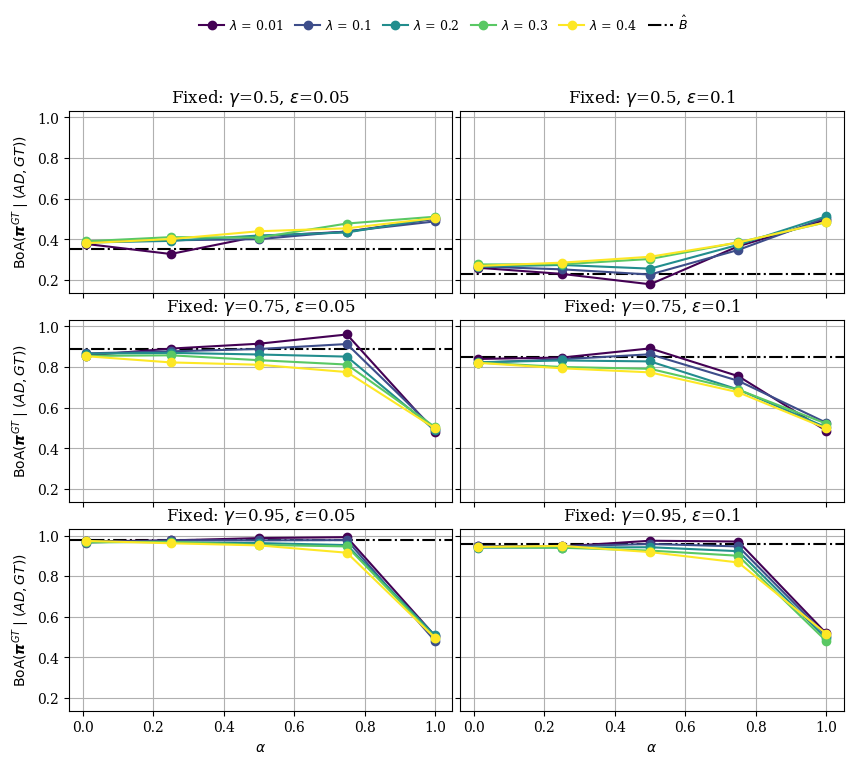

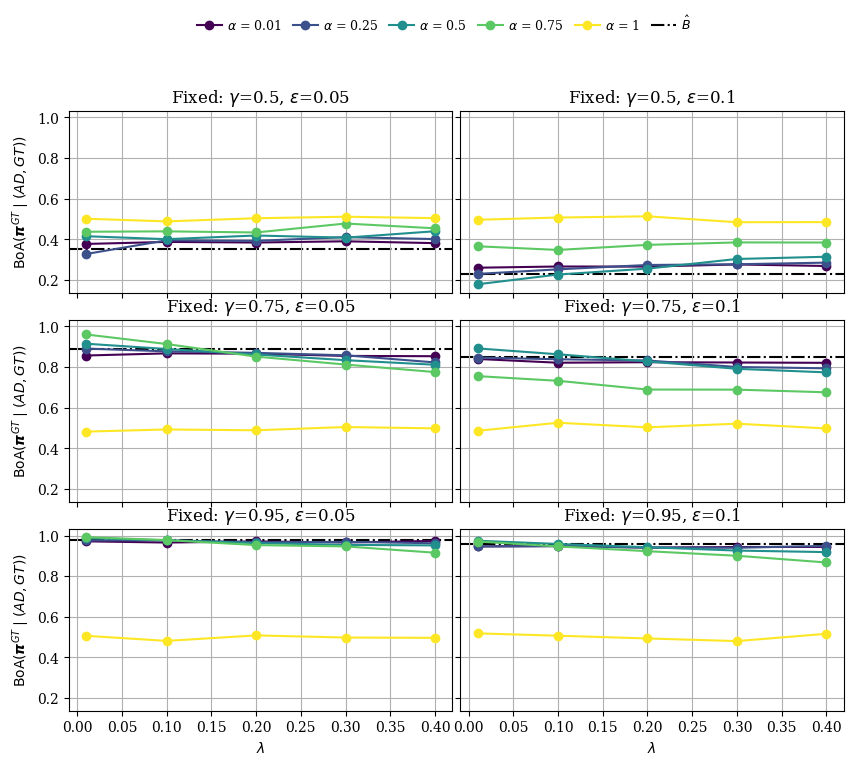

In [19]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

m=2000
y = 'P_GT'
from MultiAgent.basin import theoretical_P_AD_from_ADGT
theoretical_per_panel_c = [theoretical_P_GT_from_ADGT(t=1, r=0.7, p=0.2, s=0, delta=ps['delta'], e=ps['e']) for ps in param_sets]

plot_multiple_panels(df_ADGT0702, param_sets, x_var="alpha", varying_var="lambda", y_var=y, m=m, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_c, y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AD,GT))$", theoretical_line_label=r"$\hat{B}$")
plot_multiple_panels(df_ADGT0702, param_sets, x_var="lambda", varying_var="alpha", y_var=y, m=m, use_same_scale=True, cmap = 'viridis', theoretical_basin_AD=theoretical_per_panel_c, y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AD,GT))$", theoretical_line_label=r"$\hat{B}$")


## ACGT Plots


In [20]:
from MultiAgent.basin import theoretical_P_AD_from_ADGT


In [21]:
# Theory helpers are defined in the Proposition17 cell above (imports from basin.py).



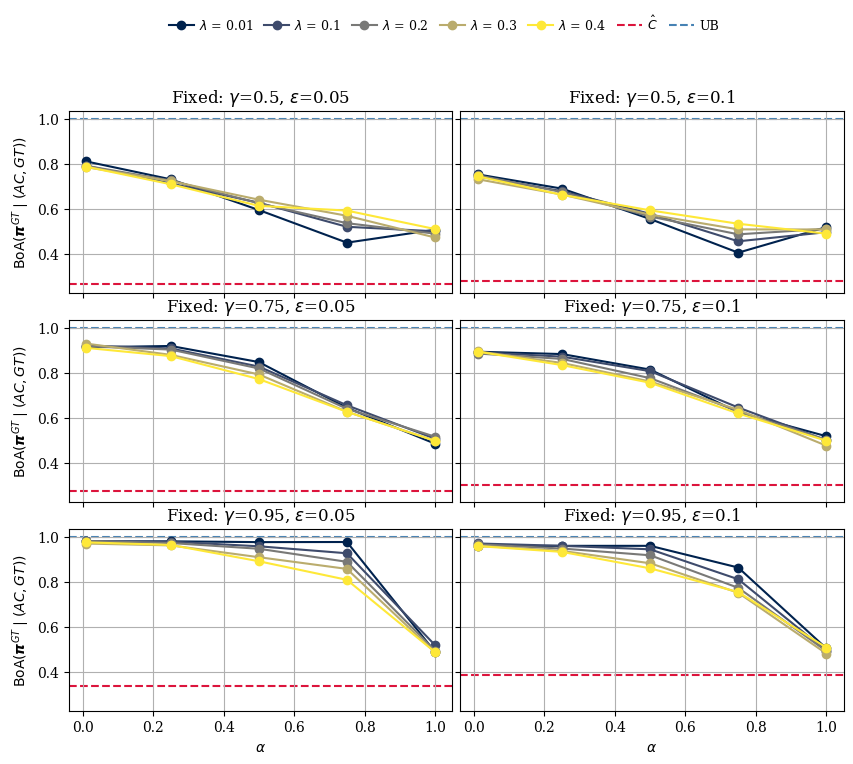

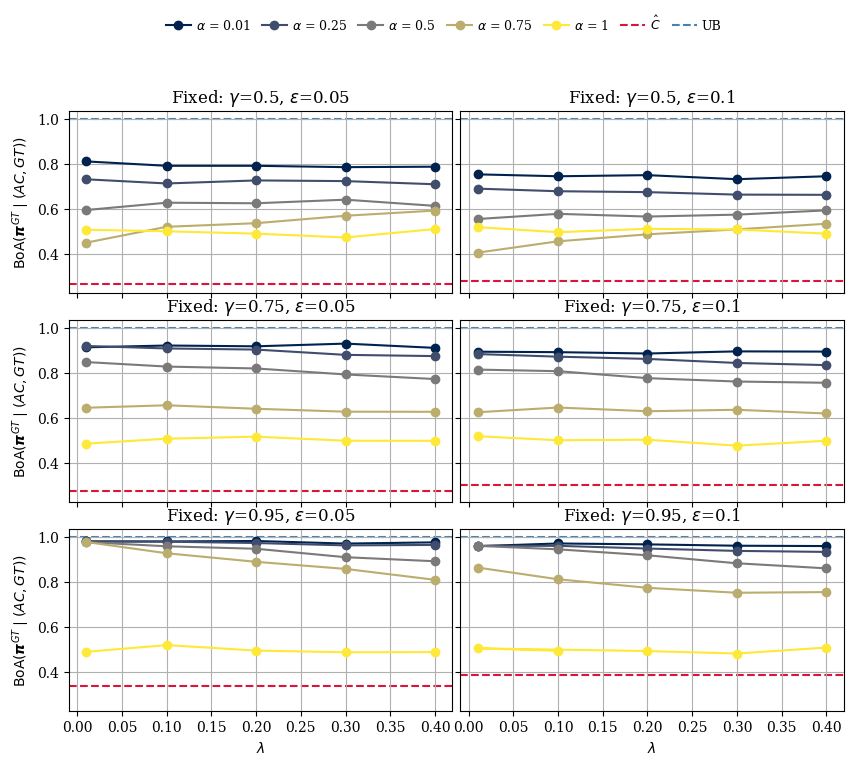

In [22]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

y = 'P_GT'
t, r, p, s = 1, 0.8, 0.4, 0

# Latex reference (ACGT): C-hat <= BoA(pi^GT | (AC,GT)) <= 1
theoretical_bounds_acgt = [
    (theoretical_C_hat_from_ACGT(t=t, r=r, p=p, s=s, delta=ps['delta'], epsilon=ps['e']), 1.0)
    for ps in param_sets
]

plot_multiple_panels(
    df_ACGT0805, param_sets, x_var="alpha", varying_var="lambda", y_var=y,
    m=2000, use_same_scale=True, cmap='cividis',
    theoretical_bounds=theoretical_bounds_acgt,
    theoretical_bounds_labels=(r"$\hat{C}$", "UB"),
    y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,GT))$"
)
plot_multiple_panels(
    df_ACGT0805, param_sets, x_var="lambda", varying_var="alpha", y_var=y,
    m=2000, use_same_scale=True, cmap='cividis',
    theoretical_bounds=theoretical_bounds_acgt,
    theoretical_bounds_labels=(r"$\hat{C}$", "UB"),
    y_axis_label=r"$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,GT))$"
)


## Boundary validation (Prop. 17)

Analytic basins $\hat B$, $\hat C$, $\hat D$ and aggregate LB/UB with simulation trajectories overlaid. Green/orange/purple shading is the **true** $\alpha\to 0$ boundary; trajectories should stay in the region determined by their initial point.

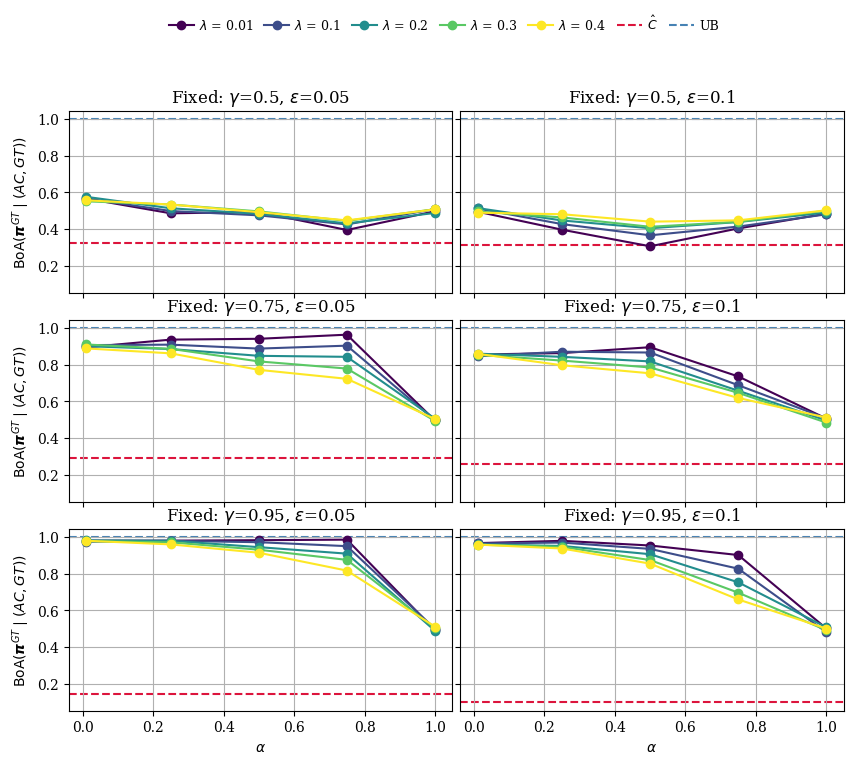

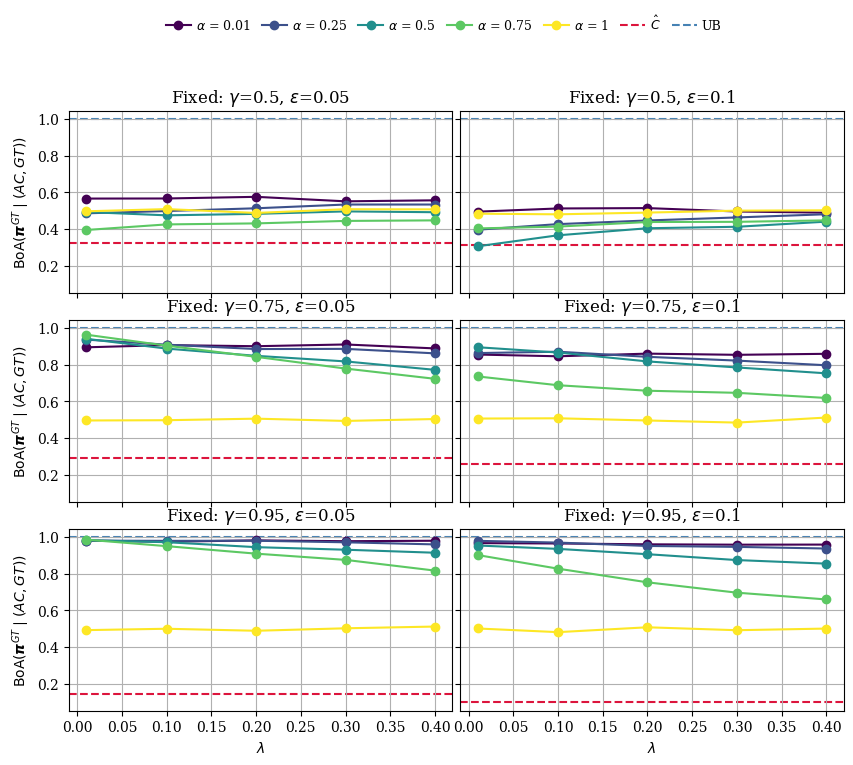

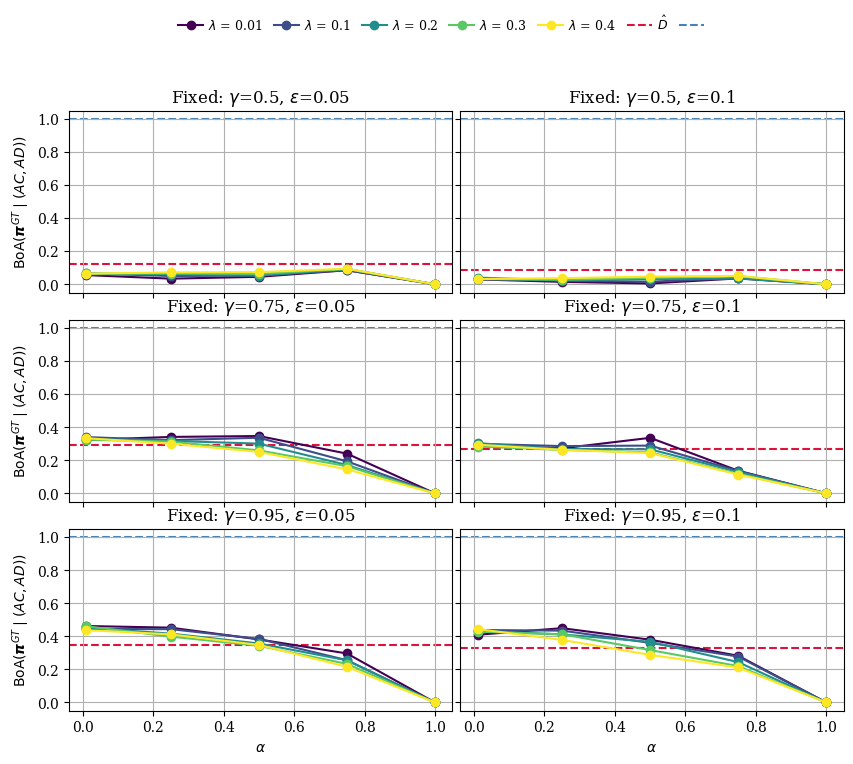

In [23]:
param_sets = [
    {'delta': 0.5, 'e': 0.05},
    {'delta': 0.5, 'e': 0.1},
    {'delta': 0.75, 'e': 0.05},
    {'delta': 0.75, 'e': 0.1},
    {'delta': 0.95, 'e': 0.05},
    {'delta': 0.95, 'e': 0.1},
]

y = 'P_GT'
t, r, p, s = 1, 0.7, 0.2, 0

theoretical_bounds_acgt = [
    (theoretical_C_hat_from_ACGT(t=t, r=r, p=p, s=s, delta=ps['delta'], epsilon=ps['e']), 1.0)
    for ps in param_sets
]

plot_multiple_panels(
    df_ACGT0702, param_sets, x_var='alpha', varying_var='lambda', y_var=y,
    m=2000, use_same_scale=True, cmap='viridis',
    theoretical_bounds=theoretical_bounds_acgt,
    theoretical_bounds_labels=(r'$\hat{C}$', 'UB'),
    y_axis_label=r'$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,GT))$',
)
plot_multiple_panels(
    df_ACGT0702, param_sets, x_var='lambda', varying_var='alpha', y_var=y,
    m=2000, use_same_scale=True, cmap='viridis',
    theoretical_bounds=theoretical_bounds_acgt,
    theoretical_bounds_labels=(r'$\hat{C}$', 'UB'),
    y_axis_label=r'$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,GT))$',
)

if df_ACAD0702 is not None:
    theoretical_d_0702 = [
        (theoretical_D_hat_from_ACAD(t=t, r=r, p=p, s=s, delta=ps['delta'], e=ps['e']), 1.0)
        for ps in param_sets
    ]
    plot_multiple_panels(
        df_ACAD0702, param_sets, x_var='alpha', varying_var='lambda', y_var=y, m=2000,
        use_same_scale=True, cmap='viridis', theoretical_bounds=theoretical_d_0702,
        theoretical_bounds_labels=(r'$\hat{D}$', None),
        y_axis_label=r'$\mathrm{BoA}(\boldsymbol{\pi}^{GT}\mid(AC,AD))$',
    )


<>:47: SyntaxWarning: invalid escape sequence '\p'
<>:47: SyntaxWarning: invalid escape sequence '\p'
/var/folders/03/nmmsz83d1rv4p3r0pt47s6ww0000gp/T/ipykernel_42107/1830410141.py:47: SyntaxWarning: invalid escape sequence '\p'
  print(f'{label}uniform aggregate BoA($\pi^{{GT}}$): LB={lb:.3f}, UB={ub:.3f}\n')


R=0.7,P=0.2 — ADGT: stays in initial GT basin = True


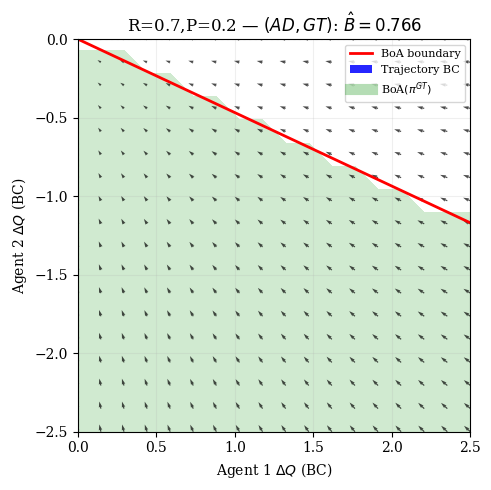

R=0.7,P=0.2 — ACGT: start in Ĉ region = 0


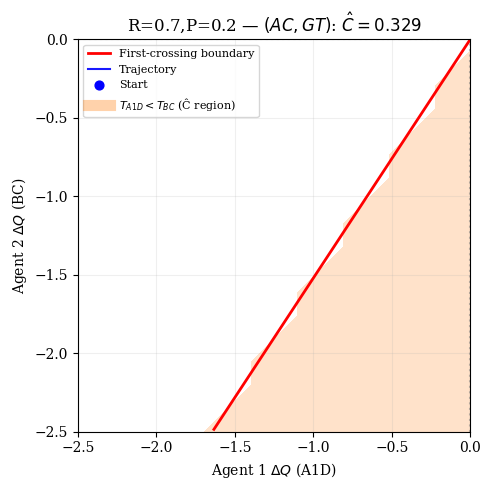

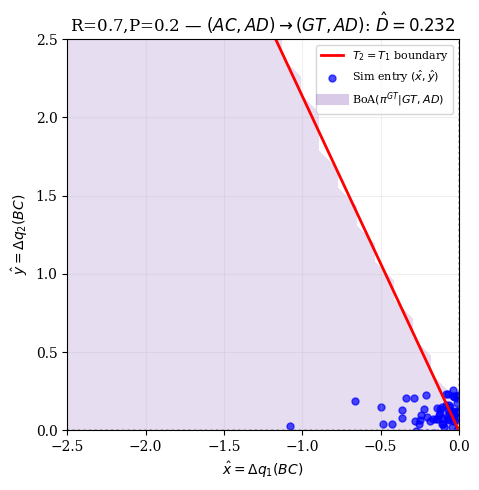

R=0.7,P=0.2 — uniform aggregate BoA($\pi^{GT}$): LB=0.228, UB=0.625

R=0.8,P=0.5 — ADGT: stays in initial GT basin = True


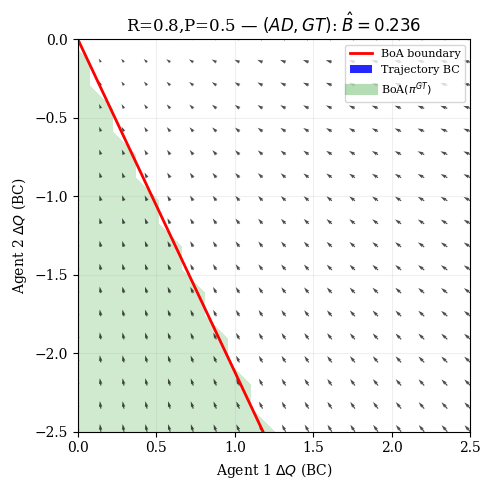

R=0.8,P=0.5 — ACGT: start in Ĉ region = 0


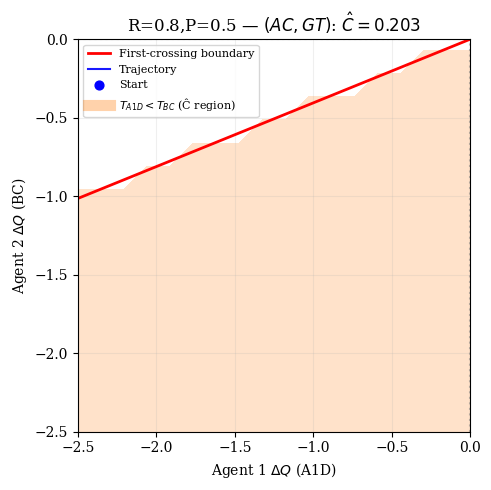

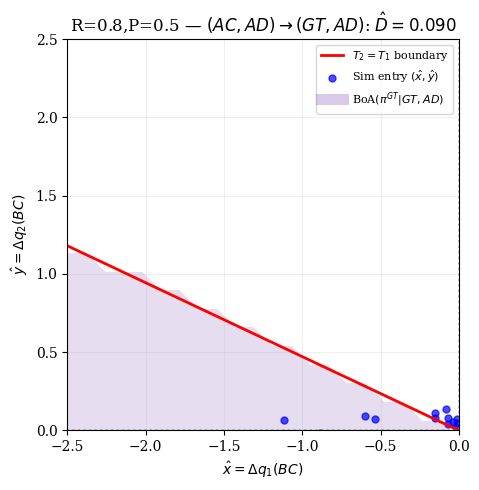

R=0.8,P=0.5 — uniform aggregate BoA($\pi^{GT}$): LB=0.129, UB=0.541



In [24]:
# Prop. 17 boundary validation: analytic shaded basins + simulation trajectories

def _run_one_trajectory(strategy1, strategy2, t, r, p, s, e, delta, alpha, lam, seed=0):
    np.random.seed(seed)
    algo = Algorithm(
        e=e, lambda_val=lam, alpha=alpha, delta=delta,
        init_mode='uniform', tolerance=1e-10, M=1,
        strategy1=strategy1, strategy2=strategy2,
        t=t, r=r, p=p, s=s, verbose=False,
    )
    q1h, q2h, _, _, _ = algo.run()
    return convert_dict_to_mean_df(q1h, mean=False)[0], convert_dict_to_mean_df(q2h, mean=False)[0]


def plot_prop17_boundaries_for_config(t, r, p, s, e, delta, alpha=0.01, lam=0.01, seed=7, label=''):
  b_hat = calculate_B_hat(t, r, p, s, e, delta)
  c_hat = calculate_C_hat(t, r, p, s, e, delta)
  d_hat = calculate_D_hat(t, r, p, s, e, delta, n_mc=150000)

  q1, q2 = _run_one_trajectory('AD', 'GT', t, r, p, s, e, delta, alpha, lam, seed=seed)
  fig, ax = plt.subplots(figsize=(6, 5))
  plot_adgt_boa_validation(
      t=t, r=r, p=p, s=s, epsilon=e, d=delta, q1=q1, q2=q2, alpha=alpha, ax=ax,
      title=rf'{label}$(AD,GT)$: $\hat{{B}}={b_hat:.3f}$',
  )
  chk = verify_trajectory_in_basin(q1, q2, 'ADGT', t, r, p, s, e, delta)
  print(f'{label}ADGT: stays in initial {chk["initial_basin"]} basin = {chk["stays_in_initial_basin"]}')
  plt.tight_layout(); plt.show()

  q1, q2 = _run_one_trajectory('AC', 'GT', t, r, p, s, e, delta, alpha, lam, seed=seed + 1)
  fig, ax = plot_acgt_boundary_validation(
      t=t, r=r, p=p, s=s, epsilon=e, d=delta, q1=q1, q2=q2, alpha=alpha,
      title=rf'{label}$(AC,GT)$: $\hat{{C}}={c_hat:.3f}$',
  )
  chk = verify_trajectory_in_basin(q1, q2, 'ACGT', t, r, p, s, e, delta)
  print(f'{label}ACGT: start in Ĉ region = {chk["initial_in_C_region"]:.0f}')
  plt.tight_layout(); plt.show()

  xh, yh = sample_acad_entry_points(t, r, p, s, e, delta, n=200, seed=seed + 2)
  fig, ax = plot_acad_entry_validation(
      t=t, r=r, p=p, s=s, epsilon=e, d=delta, entry_points=(xh, yh),
      title=rf'{label}$(AC,AD)\to(GT,AD)$: $\hat{{D}}={d_hat:.3f}$',
  )
  plt.tight_layout(); plt.show()

  lb, ub = get_aggregate_bounds_prop17(t, r, p, s, e, delta)
  print(f'{label}uniform aggregate BoA($\pi^{{GT}}$): LB={lb:.3f}, UB={ub:.3f}\n')


for cfg, name in [((1, 0.7, 0.2, 0), 'R=0.7,P=0.2 — '), ((1, 0.8, 0.5, 0), 'R=0.8,P=0.5 — ')]:
    t, r, p, s = cfg
    plot_prop17_boundaries_for_config(t, r, p, s, e=0.01, delta=0.6, alpha=0.01, lam=0.01, label=name)

In [25]:
# Overlay aggregate LB/UB on uniform-init simulation panels (total boundaries)
t, r, p, s = 1, 0.7, 0.2, 0
e, delta = 0.01, 0.6
lb, ub = get_aggregate_bounds_prop17(t, r, p, s, e, delta)
theoretical_bounds = [(lb, ub)]
print(f'Prop.17 aggregate bounds (R=0.7,P=0.2): LB={lb:.3f}, UB={ub:.3f}')

y = 'P_GT'
plot_multiple_panels(
    df_2000_0702, param_sets, x_var='alpha', varying_var='lambda', y_var=y, m=2000,
    use_same_scale=True, cmap='viridis', theoretical_bounds=theoretical_bounds,
    theoretical_bounds_labels=(r'LB $=\frac{1+2\hat B+2\hat C+2\hat D}{16}$',
                               r'UB $=\frac{8+2\hat B+2\hat D}{16}$'),
    y_axis_label=r'$\mathrm{BoA}(\boldsymbol{\pi}^{GT})$',
)

Prop.17 aggregate bounds (R=0.7,P=0.2): LB=0.228, UB=0.625


ValueError: theoretical_bounds list length must match param_sets length